# Faz 3 — Keşifsel veri analizi (EDA, exploratory data analysis)

**Bu notebook'ta ne yapacağız?** Temiz veriyi (`clean/countries_1950_2100.csv`) tanıyacağız: Göstergeler nasıl dağılıyor, zaman içinde nasıl değişiyor, birbirleriyle nasıl ilişkili?

**Neden?** Modele (Faz 5) geçmeden önce verinin "huyunu" bilmemiz gerekiyor. Çarpık dağılımlar, aşırı ilişkili değişkenler ve tarihsel şoklar modelin sonucunu etkiler. Bunları önceden görürsek doğru kararlar veririz.

**Nasıl çalışacaksın?**
1. Hücreleri tek tek **Shift+Enter** ile çalıştır.
2. Grafiklere bakmadan geçme. Her grafiğin altındaki "Nasıl okunur?" kısmını oku.
3. 🟡 işaretli sorularda dur ve cevabını sohbete yaz.

| Bölüm | Soru | 🟡 |
|---|---|---|
| A | Göstergeler 2023'te nasıl dağılıyor? | Soru 1 |
| B | Dünya 1950–2100 arasında nasıl değişiyor? Türkiye nerede? | Soru 2 |
| C | Muhasebe denklemleri 200 ülkede tutuyor mu? | Soru 3 |
| D | Doğurganlık ile yaşam beklentisi birlikte nasıl hareket ediyor? | Soru 4 |
| E | Hangi değişkenler aynı bilgiyi taşıyor? (korelasyon, çoklu doğrusal bağlantı) | Soru 5 |
| F | **K2 kararı:** EDA'yı hangi tema etrafında derinleştireceğiz? | K2 |

## Hazırlık — Veriyi oku ve K1'i uygula

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

df = pd.read_csv("../clean/countries_1950_2100.csv")

# K1 kararı: 2023 nüfusu >= 100 bin
d = df[df["pop2023"] >= 100].copy()
print("Ülke sayısı:", d["LocID"].nunique(), "| Satır:", len(d))

# Bütün projede sabit renkler (renk körü dostu)
RENK = {"Türkiye": "#2a78d6", "Japan": "#eb6834", "Nigeria": "#1baf7a"}
GRI  = "#9e9e9e"

assert d["LocID"].nunique() == 200

Ülke sayısı: 200 | Satır: 30200


**Satır satır:**
- `from matplotlib.colors import LinearSegmentedColormap`: Kendi renk skalamızı yapmak için. Bölüm E'de kullanacağız.
- `d = df[df["pop2023"] >= 100].copy()`: K1 kararını **tek satırda** uyguluyoruz. Faz 2'de `pop2023` sütununu bu yüzden eklemiştik.
- `RENK`: Ülke renklerini bir kez tanımlıyoruz. Böylece Türkiye her grafikte aynı mavi olur.

---
## A — Göstergeler 2023'te nasıl dağılıyor? (dağılım, distribution)

**Neden 2023?** Son **tahmin** yılı. Ondan sonrası projeksiyon.

**Neden dağılıma bakıyoruz?** Faz 5'te PCA ve kümeleme yapacağız. Bu yöntemler uzaklık ve varyans kullanır, bu yüzden **çarpık (skewed)** dağılımlar ve uç değerler sonucu çarpıtabilir. Önce dağılımların şekline bakmalıyız.

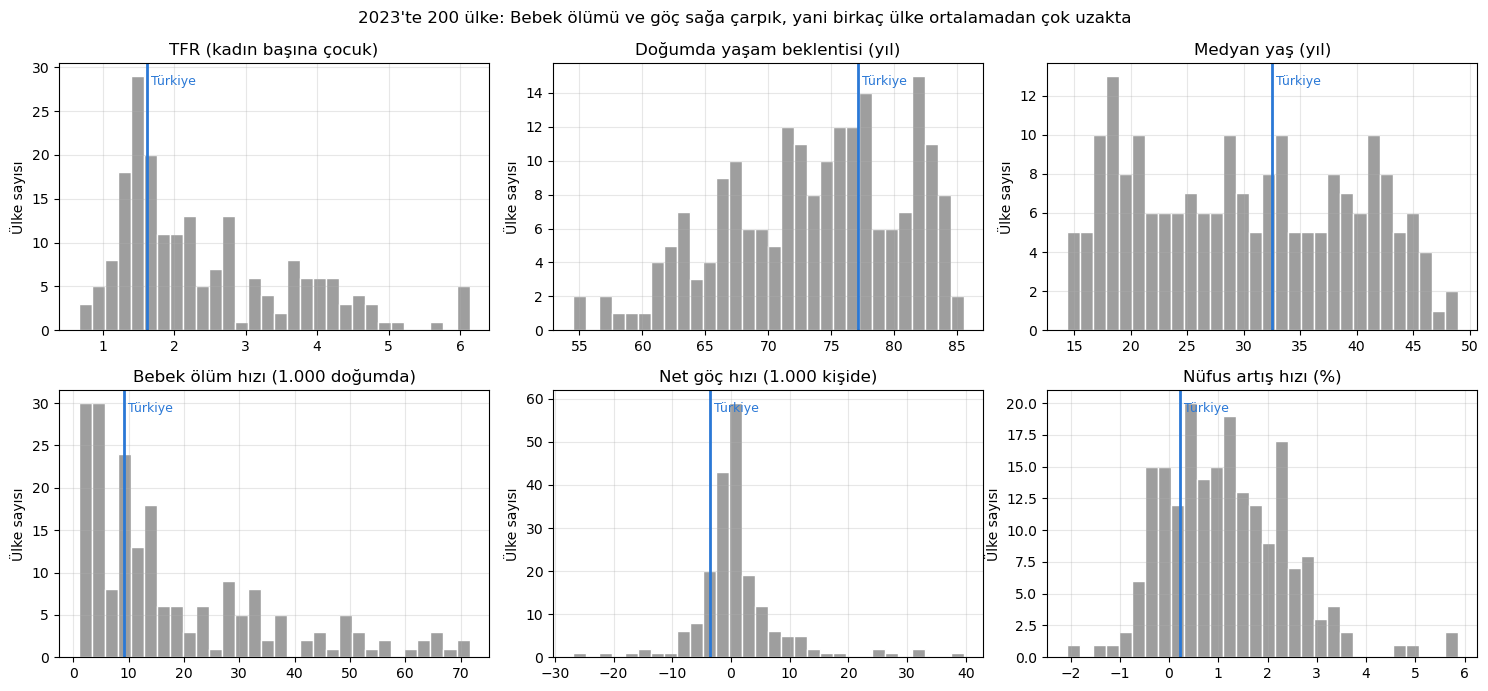

Çarpıklık (skewness): 0'a yakın = simetrik, > 1 = belirgin sağa çarpık
TFR              1.03
LEx             -0.43
MedianAgePop     0.11
IMR              1.31
CNMR             1.50
PopGrowthRate    0.68
dtype: float64


In [11]:
x = d[d["Time"] == 2023]
tr23 = x[x["Location"] == "Türkiye"].iloc[0]

gosterge = [("TFR", "TFR (kadın başına çocuk)"),
            ("LEx", "Doğumda yaşam beklentisi (yıl)"),
            ("MedianAgePop", "Medyan yaş (yıl)"),
            ("IMR", "Bebek ölüm hızı (1.000 doğumda)"),
            ("CNMR", "Net göç hızı (1.000 kişide)"),
            ("PopGrowthRate", "Nüfus artış hızı (%)")]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (col, baslik) in zip(axes.flat, gosterge):
    ax.hist(x[col], bins=30, color=GRI, edgecolor="white")
    ax.axvline(tr23[col], color=RENK["Türkiye"], lw=2)
    ax.text(tr23[col], ax.get_ylim()[1] * 0.92, " Türkiye", color=RENK["Türkiye"], fontsize=9)
    ax.set_title(baslik); ax.set_ylabel("Ülke sayısı"); ax.grid(alpha=.3)
fig.suptitle("2023'te 200 ülke: Bebek ölümü ve göç sağa çarpık, yani birkaç ülke ortalamadan çok uzakta")
plt.tight_layout(); plt.savefig("../outputs/03_A_dagilimlar_2023.png", dpi=150); plt.show()

print("Çarpıklık (skewness): 0'a yakın = simetrik, > 1 = belirgin sağa çarpık")
print(x[[c for c, _ in gosterge]].skew().round(2))

**Satır satır:**
- `x = d[d["Time"] == 2023]`: Sadece 2023 satırları, her ülkeden bir satır.
- `tr23 = ...iloc[0]`: Türkiye'nin 2023 satırı. `iloc[0]`, tablodaki ilk (ve tek) satırı alır.
- `plt.subplots(2, 3)`: 2 satır × 3 sütun = 6 panel. `axes.flat`, bu 6 paneli sırayla dolaşmayı sağlar.
- `ax.hist(x[col], bins=30)`: **Histogram**. Değerleri 30 kutuya böler ve her kutuya kaç ülke düştüğünü sayar.
- `ax.axvline(tr23[col])`: Türkiye'nin değerini dikey bir mavi çizgiyle gösterir.
- `.skew()`: **Çarpıklık katsayısı.** 0 simetrik demek. Pozitifse sağ kuyruk uzun: Çoğu ülke solda toplanmış, birkaç ülke çok sağda.

**Nasıl okunur?** Bir histogramda tepenin yerine (çoğu ülke nerede), kuyruğa (uçta kimler var) ve Türkiye'nin konumuna bak.

🟡 **Soru 1:**
1. Hangi iki göstergenin çarpıklığı 1'in üstünde? Histogramda bu nasıl görünüyor?
2. Türkiye, TFR ve medyan yaşta dünyanın neresinde: solda mı, ortada mı, sağda mı?
3. **(Düşün)** Bebek ölüm hızında (IMR) çoğu ülke 0–20 arasında, birkaç ülke 50'nin üstünde. Kümeleme bu birkaç ülkeye mi, yoksa çoğunluğa mı daha çok "dikkat eder"? Neden?

---
## B — Dünya 1950–2100 arasında nasıl değişiyor?

**Fikir:** 200 ülkeyi tek tek çizersek grafik bir yumak olur. Bunun yerine her yıl için ülkelerin **dağılımını** özetleyeceğiz:
- **Medyan ülke:** Ülkelerin tam ortasındaki değer (koyu gri çizgi).
- **%80 bandı:** Ülkelerin ortadaki %80'inin bulunduğu aralık. Alt sınırı 10. yüzdelik (percentile), üst sınırı 90. yüzdelik (açık gri alan).

**Bant daralıyorsa** ülkeler birbirine benziyor demektir. Buna **yakınsama (convergence)** denir. **Bant genişliyorsa** ülkeler birbirinden ayrışıyor demektir (ıraksama, divergence).

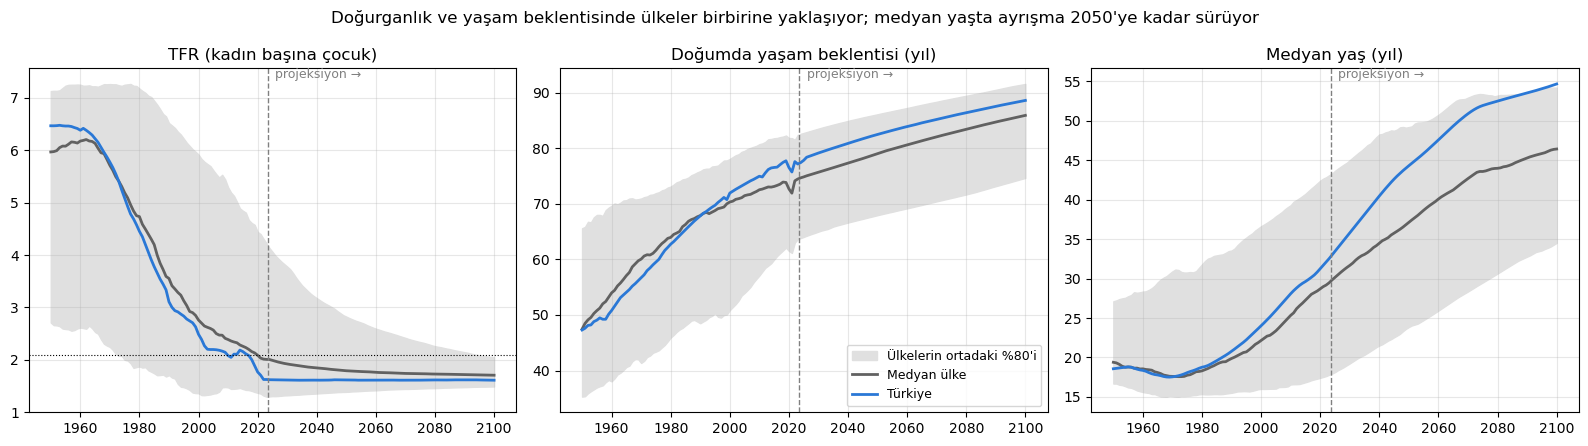

%80 bandının genişliği (90. yüzdelik − 10. yüzdelik):
       TFR    LEx  MedianAgePop
Time                           
1950  4.42  30.29         10.43
1990  4.81  27.37         18.03
2023  2.93  18.76         25.27
2050  1.44  18.15         25.33
2100  0.56  16.91         19.68


In [12]:
paneller = [("TFR", "TFR (kadın başına çocuk)"),
            ("LEx", "Doğumda yaşam beklentisi (yıl)"),
            ("MedianAgePop", "Medyan yaş (yıl)")]
tr = d[d["Location"] == "Türkiye"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, baslik) in zip(axes, paneller):
    q = d.groupby("Time")[col].quantile([0.1, 0.5, 0.9]).unstack()
    ax.fill_between(q.index, q[0.1], q[0.9], color="#e0e0e0", label="Ülkelerin ortadaki %80'i")
    ax.plot(q.index, q[0.5], color="#616161", lw=2, label="Medyan ülke")
    ax.plot(tr["Time"], tr[col], color=RENK["Türkiye"], lw=2, label="Türkiye")
    ax.axvline(2023.5, ls="--", color="gray", lw=1)
    ax.text(2026, ax.get_ylim()[1], "projeksiyon →", color="gray", fontsize=9, va="top")
    ax.set_title(baslik); ax.grid(alpha=.3)
axes[0].axhline(2.1, color="black", lw=.8, ls=":")
axes[1].legend(loc="lower right", fontsize=9)
fig.suptitle("Doğurganlık ve yaşam beklentisinde ülkeler birbirine yaklaşıyor; medyan yaşta ayrışma 2050'ye kadar sürüyor")
plt.tight_layout(); plt.savefig("../outputs/03_B_dunya_trendleri.png", dpi=150); plt.show()

genislik = d.groupby("Time")[[c for c, _ in paneller]].quantile(0.9) - d.groupby("Time")[[c for c, _ in paneller]].quantile(0.1)
print("%80 bandının genişliği (90. yüzdelik − 10. yüzdelik):")
print(genislik.loc[[1950, 1990, 2023, 2050, 2100]].round(2))

**Satır satır:**
- `d.groupby("Time")[col].quantile([0.1, 0.5, 0.9])`: Her yıl için o göstergenin 10., 50. (medyan) ve 90. yüzdeliklerini hesaplar.
- `.unstack()`: Sonucu, her yüzdeliği ayrı bir sütun yapan bir tabloya çevirir: `q[0.1]`, `q[0.5]`, `q[0.9]`.
- `ax.fill_between(x, alt, ust)`: İki çizgi arasını boyar. Bant böyle oluşuyor.
- `genislik`: 90. yüzdelik eksi 10. yüzdelik. Bandın her yıldaki genişliği. Bu sayı küçülüyorsa yakınsama var demektir.

🟡 **Soru 2:**
1. Tablodaki bant genişliklerine bak. TFR ve LEx'te bant daralıyor mu? Medyan yaşta ne oluyor: Hep daralıyor mu, önce genişleyip sonra mı daralıyor? Sence neden?
2. Türkiye TFR'de 1950'de bandın neresindeydi, 2023'te nerede? Ya medyan yaşta, 2100'de?
3. **(Etik, düşün)** 2024 sonrası bant **UN'in varsayımlarından** geliyor. UN, "her ülkenin TFR'si uzun vadede 1,5–1,8 civarına gider" gibi bir varsayım kullanıyorsa, bandın daralması **gerçek bir bulgu mu, yoksa varsayımın sonucu mu**?

### B2 — Açık bir soruyu kapatalım: Türkiye'nin yaşam beklentisi 2020'lerde neden düştü?

Faz 1'de Türkiye'nin LEx grafiğinde 2020–2023 arasında bir çukur görmüştük. O gün, olası sebepleri **"henüz doğrulanmadı"** diye not ettik. Şimdi veriye bakalım.

In [13]:
tr.set_index("Time").loc[2017:2025, ["LEx", "LExMale", "LExFemale", "Deaths", "CDR"]].round(2)

,LEx,LExMale,LExFemale,Deaths,CDR
Time,,,,,
2017,77.04,73.96,80.25,469.48,5.65
2018,77.45,74.39,80.63,468.09,5.54
2019,77.74,74.68,80.89,471.14,5.52
2020,76.53,73.44,79.89,566.48,6.58
2021,75.72,72.72,79.00,640.53,7.39
2022,77.59,74.65,80.72,555.77,6.38
2023,77.16,74.53,79.86,551.60,6.32
2024,77.42,74.62,80.34,580.40,6.64
2025,77.82,74.94,80.82,576.12,6.57


**Nasıl okunur?**
- `Deaths`: Yıllık ölüm sayısı (bin kişi). `CDR`: 1.000 kişi başına ölüm.
- **2020–2021:** Ölümler yılda yaklaşık 470 binden **566 ve 640 bine** çıkıyor. LEx 77,7'den **75,7'ye** düşüyor, sonra 2022'de toparlanıyor. Bu desen **COVID-19 pandemisiyle tutarlı (consistent with).**
- **2023:** LEx 77,6'dan **77,2'ye** tekrar düşüyor. Bu düşüş Şubat 2023 depremleriyle tutarlı. Toplam ölüm sayısı çok değişmiyor, ama depremde **gençler de** hayatını kaybetti. Genç yaşta bir ölüm, yaşam beklentisini yaşlı bir ölümden daha çok düşürür.

**Neden "tutarlı" diyoruz, "sebebi bu" demiyoruz?** Bu veride ölüm **sebebi** yok. Sadece toplam ölüm ve yaşam beklentisi var. Zamanlama, bilinen olaylarla örtüşüyor. Ama sebebi kanıtlamak için ölüm nedeni verisi gerekir.

**Jüri sorarsa:** *"The dip matches the timing of COVID-19 in 2020–21 and the 2023 earthquakes. Our data has no cause-of-death information, so we describe it as consistent with these events, not caused by them."*

---
## C — Muhasebe denklemleri 200 ülkede tutuyor mu?

Faz 1'de Türkiye için şunu doğruladık: **Nüfus değişimi = Doğal artış + Net göç** (demografik denge denklemi). Şimdi iki denklemi 200 ülkenin bütün yıllarında kontrol edeceğiz:
1. `PopChange = NatChange + NetMigrations` (sayılarla)
2. `PopGrowthRate ≈ (NatChangeRT + CNMR) / 10` (oranlarla)
   - `NatChangeRT` ve `CNMR` 1.000 kişi başına. `PopGrowthRate` ise yüzde. 1.000'de x = yüzde x/10 olduğu için 10'a bölüyoruz.

**Neden?** Verinin iç tutarlılığını (internal consistency) test etmek için. Jüriye "veriyi körü körüne kullanmadık" diyebilmemizin kanıtı bu.

In [14]:
# 1) Sayılarla: göreli fark (% olarak)
fark1 = (d["PopChange"] - (d["NatChange"] + d["NetMigrations"])).abs() / d["TPopulation1Jan"] * 100
print("Denklem 1 — ülke-yılların %99'unda fark şundan küçük (%):", round(fark1.quantile(0.99), 4))

# 2) Oranlarla
d["fark2"] = (d["PopGrowthRate"] - (d["NatChangeRT"] + d["CNMR"]) / 10).abs()
print("Denklem 2 — farkın medyanı:", round(d["fark2"].median(), 4), "yüzde puan")
print("Denklem 2 — fark 0,1 puandan büyük olan ülke-yıl:", (d["fark2"] > 0.1).sum(), "/", len(d))
print()
print("Denklemin en çok saptığı 6 ülke-yıl:")
d.nlargest(6, "fark2")[["Location", "Time", "PopGrowthRate", "NatChangeRT", "CNMR", "fark2"]].round(1)

Denklem 1 — ülke-yılların %99'unda fark şundan küçük (%): 0.0096
Denklem 2 — farkın medyanı: 0.0003 yüzde puan
Denklem 2 — fark 0,1 puandan büyük olan ülke-yıl: 14 / 30200

Denklemin en çok saptığı 6 ülke-yıl:


,Location,Time,PopGrowthRate,NatChangeRT,CNMR,fark2
16499,Kuwait,1990,-71.1,27.7,-709.9,2.8
26318,Rwanda,1994,-41.8,-105.9,-305.9,0.6
13604,"China, Hong Kong SAR",1964,37.9,17.3,357.1,0.4
18134,"China, Macao SAR",1964,37.1,12.2,354.5,0.4
16500,Kuwait,1991,36.1,16.2,340.9,0.4
13607,"China, Hong Kong SAR",1967,-33.0,31.7,-359.3,0.3


**Satır satır:**
- `fark1`: Denklemin iki tarafı arasındaki farkı nüfusa bölüp 100 ile çarpar. Böylece fark, nüfusun yüzdesi olarak ifade edilir.
- `quantile(0.99)`: Ülke-yılların %99'u bu değerin altında demek.
- `d.nlargest(6, "fark2")`: Farkın en büyük olduğu 6 satırı getirir.

**Nasıl okunur?** 30.200 ülke-yılın neredeyse hepsinde iki denklem de tutuyor. Sapma görülen birkaç yer ise **tarihin kendisi**:
- **Kuwait 1990–1991:** Irak'ın işgali. Net göç hızı 1.000 kişide **−710**. Nüfusun büyük kısmı bir yılda ülkeyi terk etti.
- **Rwanda 1994:** Soykırım ve kitlesel mülteci hareketi.
- **Hong Kong ve Macao 1960'lar:** Çin anakarasından büyük göç dalgaları.

**Neden tam bu yıllarda sapıyor?** `PopGrowthRate` **logaritmik (üstel) bir hız**: r = ln(P₁/P₀). Sağ taraf ise **basit bir oran**. Değişim küçükken ikisi neredeyse eşit, çünkü küçük x için ln(1+x) ≈ x. Değişim çok büyük olduğunda (örneğin nüfusun yarısı gidince) bu yaklaşıklık bozuluyor. Yani sapmanın sebebi bir veri hatası değil, **matematiksel bir yaklaşıklığın sınırı.**

**Etik not:** Bu yılların arkasında savaş ve soykırım var. Sunumda bu ülkelerden söz edersek, insan kaybını bir "uç değer (outlier)" gibi anlatmadan, saygılı bir dil kullanmalıyız.

🟡 **Soru 3:**
1. Denklem 1 neden 200 ülkede tutuyor, ama Denklem 2 birkaç yerde bozuluyor? Kendi kelimelerinle açıkla.
2. Kümeleme yaparken Kuwait 1990 gibi tek yıllık şoklar sonucu etkiler mi? **İpucu:** Ülkeleri 150 yıllık **seyirlerine** göre gruplayacağız.

---
## D — Doğurganlık ile yaşam beklentisi birlikte nasıl hareket ediyor?

**Demografik dönüşüm (demographic transition)** kuramı şunu söyler: Ülkeler zamanla "çok doğum, kısa ömür" durumundan "az doğum, uzun ömür" durumuna geçer.

Bunu görmek için her ülkeyi bir nokta olarak çizeceğiz: yatay eksen **TFR**, dikey eksen **LEx**. Bu grafiği dört farklı yıl için yan yana koyacağız.

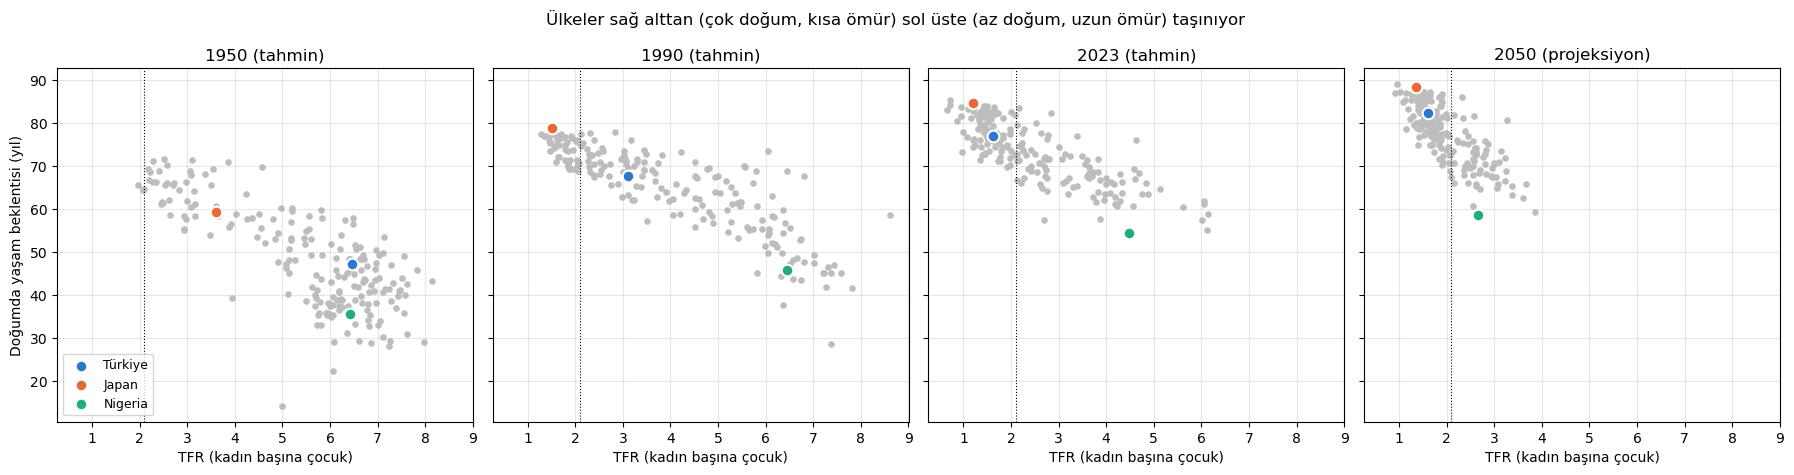

1950 → TFR–LEx korelasyonu: -0.77
1990 → TFR–LEx korelasyonu: -0.85
2023 → TFR–LEx korelasyonu: -0.82
2050 → TFR–LEx korelasyonu: -0.79


In [15]:
yillar = [1950, 1990, 2023, 2050]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8), sharex=True, sharey=True)
for ax, yil in zip(axes, yillar):
    z = d[d["Time"] == yil]
    ax.scatter(z["TFR"], z["LEx"], s=14, color="#bdbdbd")
    for ulke, renk in RENK.items():
        r = z[z["Location"] == ulke]
        ax.scatter(r["TFR"], r["LEx"], s=70, color=renk, edgecolor="white", linewidth=1.5, zorder=3, label=ulke)
    ax.axvline(2.1, color="black", lw=.8, ls=":")
    ax.set_title(f"{yil}" + (" (projeksiyon)" if yil > 2023 else " (tahmin)"))
    ax.set_xlabel("TFR (kadın başına çocuk)"); ax.grid(alpha=.3)
axes[0].set_ylabel("Doğumda yaşam beklentisi (yıl)")
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle("Ülkeler sağ alttan (çok doğum, kısa ömür) sol üste (az doğum, uzun ömür) taşınıyor")
plt.tight_layout(); plt.savefig("../outputs/03_D_tfr_lex.png", dpi=150); plt.show()

for yil in yillar:
    z = d[d["Time"] == yil]
    print(yil, "→ TFR–LEx korelasyonu:", round(z["TFR"].corr(z["LEx"]), 2))

**Satır satır:**
- `sharex=True, sharey=True`: Dört panelin eksenleri **aynı ölçekte**. Böylece noktaların hareketi paneller arasında doğrudan karşılaştırılabilir. Ortak ölçek kullanmasaydık her panel kendi ölçeğini seçer ve hareket gizlenirdi.
- `ax.scatter(...)`: Saçılım grafiği (scatter plot). Her nokta bir ülke.
- İkinci `scatter`: Üç ülkeyi büyük, renkli ve beyaz kenarlı noktalarla öne çıkarır. `zorder=3`, bu noktaların gri noktaların üstünde çizilmesini sağlar.
- `z["TFR"].corr(z["LEx"])`: **Pearson korelasyonu.** −1 ile +1 arasında. Negatifse biri artarken diğeri azalıyor demektir.

🟡 **Soru 4:**
1. Nokta bulutu 1950'den 2050'ye nasıl hareket ediyor? Türkiye ve Nijerya bu yolculukta nerede?
2. Korelasyon her yıl negatif mi? Hangi yılda en güçlü? 1950'de neden daha zayıf olabilir? **İpucu:** 1950 panelinde aynı TFR'ye sahip ülkelerin LEx değerlerine bak.
3. **(Önemli)** Bu korelasyon "doğurganlık düşünce insanlar uzun yaşar" anlamına mı gelir? Nedensellik (causality) iddia edebilir miyiz?

---
## E — Hangi değişkenler aynı bilgiyi taşıyor? (korelasyon ve çoklu doğrusal bağlantı)

**Neden?** Faz 5'te 6–8 değişken seçeceğiz (K4). İki değişken neredeyse aynı bilgiyi taşıyorsa (korelasyon ≈ ±1), ikisini birden modele koymak o bilgiyi **iki kez saymak** demektir. Faz 2'de LE60 ile LE65 için bunu görmüştük.

Önce 13 aday değişkenin 2023'teki **korelasyon matrisine** bakacağız.

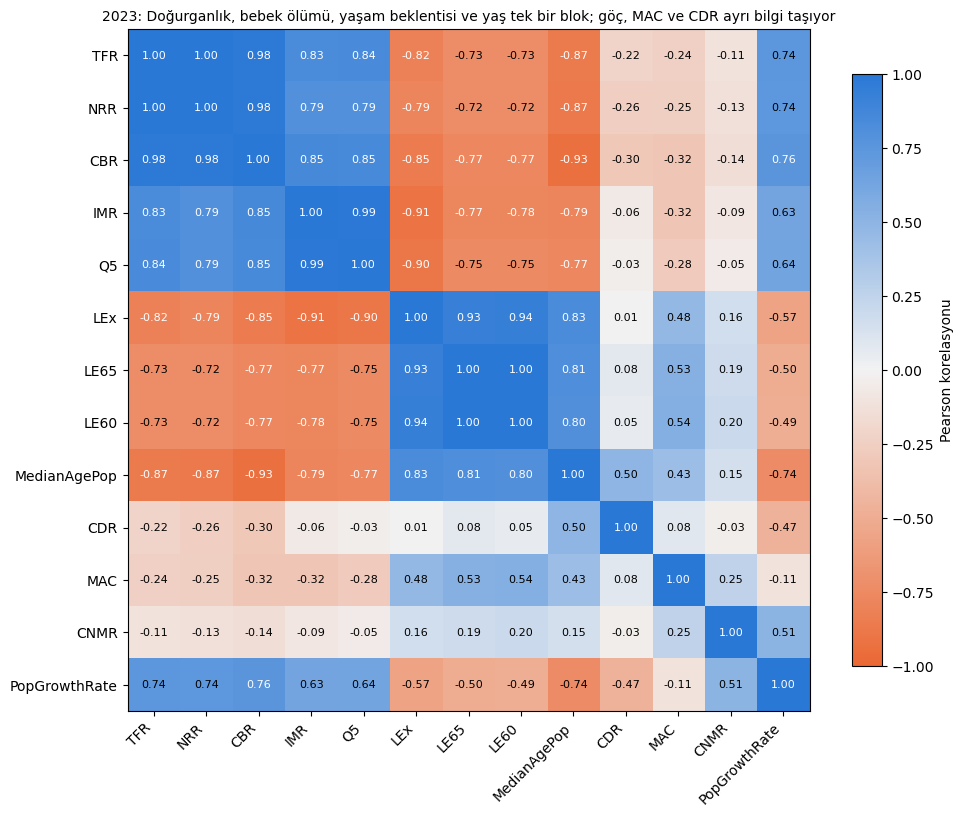

Neredeyse aynı bilgiyi taşıyan çiftler (|r| > 0.95):
LE65  LE60    0.998
TFR   NRR     0.995
IMR   Q5      0.991
TFR   CBR     0.982
NRR   CBR     0.980
dtype: float64


In [16]:
adaylar = ["TFR", "NRR", "CBR", "IMR", "Q5", "LEx", "LE65", "LE60",
           "MedianAgePop", "CDR", "MAC", "CNMR", "PopGrowthRate"]
R = x[adaylar].corr()

# Iraksak (diverging) renk skalası: −1 turuncu, 0 nötr gri, +1 mavi
skala = LinearSegmentedColormap.from_list("iraksak", ["#eb6834", "#f2f2f2", "#2a78d6"])

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(R, cmap=skala, vmin=-1, vmax=1)
ax.set_xticks(range(len(adaylar)), adaylar, rotation=45, ha="right")
ax.set_yticks(range(len(adaylar)), adaylar)
for i in range(len(adaylar)):
    for j in range(len(adaylar)):
        ax.text(j, i, f"{R.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(R.iloc[i, j]) > 0.75 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson korelasyonu")
ax.set_title("2023: Doğurganlık, bebek ölümü, yaşam beklentisi ve yaş tek bir blok; göç, MAC ve CDR ayrı bilgi taşıyor", fontsize=10)
plt.tight_layout(); plt.savefig("../outputs/03_E_korelasyon.png", dpi=150); plt.show()

# |r| > 0.95 olan çiftler
ust = R.where(np.triu(np.ones(R.shape, dtype=bool), k=1))
ciftler = ust.stack()
print("Neredeyse aynı bilgiyi taşıyan çiftler (|r| > 0.95):")
print(ciftler[ciftler.abs() > 0.95].round(3).sort_values(ascending=False))

**Satır satır:**
- `x[adaylar].corr()`: 13 × 13 korelasyon matrisi. Her hücre iki değişken arasındaki korelasyonu gösterir.
- `LinearSegmentedColormap.from_list(...)`: Üç renkten bir skala yapar. Negatif değerler turuncu, sıfır nötr gri, pozitif değerler mavi.
  - Ortanın **gri** olması bilinçli bir seçim: "İlişki yok" renksiz görünmeli.
- `imshow`: Matrisi renkli kareler halinde çizer. Bu grafiğe **ısı haritası (heatmap)** denir.
- İç içe `for`: Her karenin içine sayıyı yazar. Koyu karelerde yazı beyaz olur ki okunabilsin.
- `np.triu(..., k=1)`: Matrisin **üst üçgenini** alır. Matris simetrik (A–B = B–A), bu yüzden her çifti bir kez saymak için yarısı yeterli.
- `.stack()`: Matrisi "çift → değer" listesine çevirir.

**Nasıl okunur?** Koyu mavi ve koyu turuncu bloklar aynı bilgiyi taşıyan değişken gruplarıdır. Köşegen (diagonal) her zaman 1, çünkü her değişken kendisiyle tam ilişkilidir.

### E2 — Çoklu doğrusal bağlantı (multicollinearity): VIF

Korelasyon **iki** değişkene bakar. Ama bir değişken, **diğerlerinin birleşimiyle** de tahmin edilebilir. Bunu ölçen sayının adı **VIF (varyans şişirme faktörü, variance inflation factor)**:

**VIF = 1 / (1 − R²)**. Buradaki R², o değişkenin **diğer bütün değişkenlerle** ne kadar iyi tahmin edilebildiğini gösterir.

- VIF = 1: Diğerleriyle hiç ilişkisi yok.
- VIF > 10: **Ciddi çoklu doğrusal bağlantı.** Değişkenin bilgisi büyük ölçüde diğerlerinde zaten var.

CLAUDE.md'de modelleme için önerilen 8 değişkene bakalım. LE60 yerine, Faz 2'deki bulguya göre **LE65**'i koyuyoruz.

In [17]:
oneri8 = ["TFR", "LEx", "MedianAgePop", "IMR", "CNMR", "PopGrowthRate", "MAC", "LE65"]
R8 = x[oneri8].corr().values
vif = pd.Series(np.diag(np.linalg.inv(R8)), index=oneri8).sort_values(ascending=False)
print("VIF (önerilen 8 değişken, 2023):")
print(vif.round(1))

VIF (önerilen 8 değişken, 2023):
PopGrowthRate    86.2
MedianAgePop     42.1
CNMR             33.3
LEx              29.1
TFR              21.3
LE65              9.4
IMR               9.2
MAC               1.7
dtype: float64


**Satır satır:**
- `np.linalg.inv(R8)`: Korelasyon matrisinin **tersini (inverse)** alır.
- `np.diag(...)`: Ters matrisin köşegenini alır. Matematiksel bir sonuç: **Korelasyon matrisinin tersinin köşegeni, tam olarak VIF değerlerini verir.** Her değişken için ayrı bir regresyon kurmadan VIF'i tek satırda hesaplamış oluyoruz.

**Nasıl okunur?** `PopGrowthRate`'in VIF'i neden bu kadar yüksek? Bölüm C'yi hatırla: PopGrowthRate ≈ (doğal artış + net göç) / 10. Yani bu değişken **diğerlerinin aritmetik bir birleşimi**, yeni bir bilgi taşımıyor.

🟡 **Soru 5:**
1. Hangi çiftler neredeyse aynı (|r| > 0,95)? Her çiftten **hangisini** tutardın ve neden?
2. VIF'i 10'un üstünde olan değişkenler hangileri?
3. **(Faz 5'e köprü)** Çoklu doğrusal bağlantıyla başa çıkmanın iki yolu var: (i) bazı değişkenleri çıkarmak, (ii) **PCA** ile ilişkili değişkenleri birkaç bağımsız bileşende birleştirmek. Sence PCA bu tabloya neden çok uygun?

---
## F — 🟡 K2 kararı: EDA'yı hangi tema etrafında derinleştirelim?

Üç tema var. Her biri için basit bir soru soruyoruz: **Her yıl kaç ülke bu durumda?**
- **(a) Demografik dönüşüm:** TFR'si yenilenme düzeyinin (2,1) altında olan ülke sayısı.
- **(b) Yaşlanma:** Medyan yaşı 40'ın üstünde olan ülke sayısı.
- **(c) Göç:** Net göçün, doğal artıştan (mutlak değerce) **büyük** olduğu ülke sayısı. Yani nüfus değişimini doğum ve ölümlerden çok göçün belirlediği ülkeler.

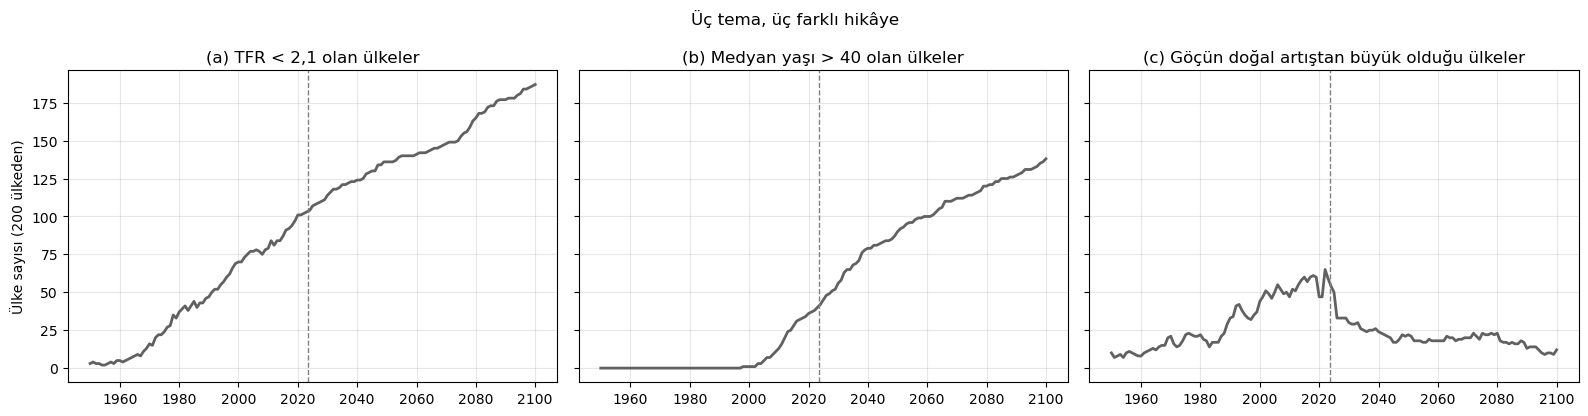

,dusuk_dogurganlik,yasli,goc_baskin
Time,,,
1950,3,0,10
1990,47,0,33
2023,103,40,59
2050,136,90,22
2100,187,138,12


In [18]:
d["dusuk_dogurganlik"] = d["TFR"] < 2.1
d["yasli"]             = d["MedianAgePop"] > 40
d["goc_baskin"]        = d["NetMigrations"].abs() > d["NatChange"].abs()
sayilar = d.groupby("Time")[["dusuk_dogurganlik", "yasli", "goc_baskin"]].sum()

basliklar = ["(a) TFR < 2,1 olan ülkeler", "(b) Medyan yaşı > 40 olan ülkeler",
             "(c) Göçün doğal artıştan büyük olduğu ülkeler"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, col, baslik in zip(axes, sayilar.columns, basliklar):
    ax.plot(sayilar.index, sayilar[col], color="#616161", lw=2)
    ax.axvline(2023.5, ls="--", color="gray", lw=1)
    ax.set_title(baslik); ax.grid(alpha=.3)
axes[0].set_ylabel("Ülke sayısı (200 ülkeden)")
fig.suptitle("Üç tema, üç farklı hikâye")
plt.tight_layout(); plt.savefig("../outputs/03_F_uc_tema.png", dpi=150); plt.show()

sayilar.loc[[1950, 1990, 2023, 2050, 2100]]

**Satır satır:**
- İlk üç satır, her ülke-yıl için **doğru/yanlış (True/False)** sütunları üretir.
- `groupby("Time")[...].sum()`: Python'da True = 1, False = 0 sayılır. Bu yüzden toplam, her yıl kaç ülkede koşulun doğru olduğunu verir.
- `sharey=True`: Üç panel aynı dikey ölçeği kullanır (0–200), böylece doğrudan karşılaştırılabilir.

**Nasıl okunur?** (a) ve (b) sürekli artıyor. (c) ise 2023'e kadar artıyor, sonra 2024–2026 arasında **birden yarıya iniyor**. Gerçek dünyada göç böyle bir anda değişmez. Bu kırılma, tahminden projeksiyona geçişte UN'in göç **varsayımının** devreye girmesinden kaynaklanıyor: UN, göçün zamanla azalacağını varsayıyor. Göç, projeksiyonun en belirsiz bileşeni.

### K2 seçenekleri
| | (a) Demografik dönüşüm | (b) Yaşlanma | (c) Göç |
|---|---|---|---|
| Güçlü yanı | Projenin ana sorusuna (seyir kümelemesi) en doğrudan bağlanan tema. TFR ve LEx en güvenilir göstergeler | Türkiye hikâyesine çok uygun (2081'de Japonya ile aynı medyan yaş) | Güncel ve ilgi çekici bir konu |
| Zayıf yanı | Literatürde iyi bilinen bir konu, yenilik bulgudan gelmeli | (a)'nın bir sonucu, ondan bağımsız değil | Projeksiyonu en belirsiz bileşen. UN göçün azalacağını varsayıyor |

🟡 **K2 kararı:** Seçimin (a), (b) veya (c), ve tek cümlelik gerekçen.

---
## Faz 3 özeti (Soru 1–5 ve K2 cevaplandıktan sonra birlikte tamamlanacak)
- **Dağılımlar:** IMR ve CNMR sağa çarpık. Faz 5'te dönüşüm (ör. logaritma) gerekebilir.
- **Yakınsama:** Ülkeler 1950–2100 arasında birbirine yaklaşıyor. Ama 2024 sonrası UN varsayımlarına dayanıyor.
- **Türkiye LEx çukuru:** 2020–2021 COVID-19 ve 2023 depremleriyle tutarlı. Nedensellik iddia edilmiyor.
- **Muhasebe denklemleri:** 200 ülkede tutuyor. Sapmalar yalnızca büyük tarihsel şoklarda.
- **TFR–LEx:** Güçlü negatif ilişki. Ülkeler zamanla aynı yolda ilerliyor.
- **Çoklu doğrusal bağlantı:** Çok güçlü. PCA için güçlü bir gerekçe.